# Setup

In [2]:
import sys
sys.path.insert(0, '/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/fast_ai/Part_2/course22p2')

import os
os.environ['CUDA_VISIBLE_DEVICES'] = '0'

import timm, torch, random, datasets, math, fastcore.all as fc, numpy as np, matplotlib as mpl, matplotlib.pyplot as plt
import k_diffusion as K, torchvision.transforms as T
import torchvision.transforms.functional as TF,torch.nn.functional as F

from torch.utils.data import DataLoader,default_collate
from pathlib import Path
from torch.nn import init
from fastcore.foundation import L
from torch import nn,tensor
from datasets import load_dataset
from operator import itemgetter
from torcheval.metrics import MulticlassAccuracy
from functools import partial
from torch.optim import lr_scheduler
from torch import optim

from miniai.datasets import *
from miniai.conv import *
from miniai.learner import *
from miniai.activations import *
from miniai.init import *
from miniai.sgd import *
from miniai.resnet import *
from miniai.augment import *
from miniai.accel import *

from fastprogress import progress_bar
from diffusers import UNet2DModel, DDIMPipeline, DDPMPipeline, DDIMScheduler, DDPMScheduler

torch.set_printoptions(precision=5, linewidth=140, sci_mode=False)
torch.manual_seed(1)
mpl.rcParams['image.cmap'] = 'gray_r'
mpl.rcParams['figure.dpi'] = 70

import logging
logging.disable(logging.WARNING)

set_seed(42)
if fc.defaults.cpus>8: fc.defaults.cpus=8

In [3]:
torch.cuda.is_available()

True

In [4]:
xl,yl = 'image','label'
name = "fashion_mnist"
n_steps = 1000
bs = 256
dsd = load_dataset(name)

In [5]:
@inplace
def transformi(b): b[xl] = [F.pad(TF.to_tensor(o), (2,2,2,2))*2-1 for o in b[xl]]

tds = dsd.with_transform(transformi)
dls = DataLoaders.from_dd(tds, bs)

dl = dls.train
xb,yb = b = next(iter(dl))

# Noisify, etc...

In [6]:
xb.std()

tensor(0.66330)

In [7]:
sig_data = 0.66 # I tried not only one batch, much more and it is still 0.66

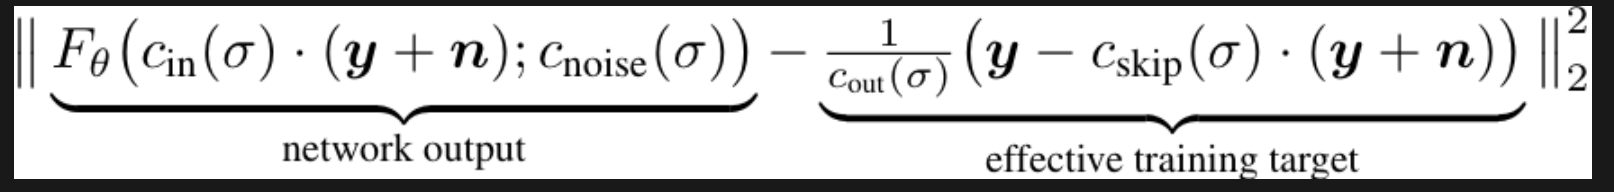
`y` is clean signal, `n` is `N(0,1)` noise.
- This is the MSE equation $\|\mathbf{whatever}\|_2^2$ where, $\|a - b\|_2^2 = \sum_{i=1}^{n}(a_i - b_i)^2$, They just in paper skip writing the 1/n (mean)

In [8]:
def scaling(sig):
    totvar = sig**2 + sig_data**2
    return sig_data**2/totvar, sig*sig_data/totvar.sqrt(), 1/totvar.sqrt() # c_skip,c_out,c_in

Normalize:
- `c_in` -> noised input for model
- `c_out`-> model target (we divide it by this)

 $Var(X + Y) = Var(X) + Var(Y)$

    IMPORTANT: c_skip = sig_data²/totvar
        at low sig:  sig≈0 → totvar≈sig_data² → c_skip≈1 (predict noise)
            - low sig (almost clean):
                c_skip ≈ 1
                target = (x0 - 1*noised_input) / c_out
                       = (x0 - (x0+noise*sig)) / c_out
                       = -noise*sig / c_out
                        model predicts scaled noise ✓

        at high sig: sig huge → totvar≈sig² → c_skip≈0 (predict the image)
            - high sig (lots of noise):
                 c_skip ≈ 0
                 target = (x0 - 0*noised) / c_out ≈ x0/c_out
                 model predicts scaled clean image ✓

    c_in = 1/sqrt(totvar)
        divide input by total std = normalize to unit variance

    c_out = sig*sig_data/sqrt(totvar)
        scales model output

In [9]:
sig_samp = (torch.randn([10000])*1.2-1.2).exp()
sig_samp.shape

torch.Size([10000])

    - sigma = standard deviation of noise added
        sigma=0.1  → tiny noise, barely changes image
        sigma=10   → lots of noise, image blurry
        sigma=80   → pure noise, image destroyed ✓

    Sigma is just the knob that controls noise amount. Everything else is clever
    math built around it to...

- `.exp()` -> e^(each value)
- Most values cluster around `e^(-1.2) ≈ 0.3`

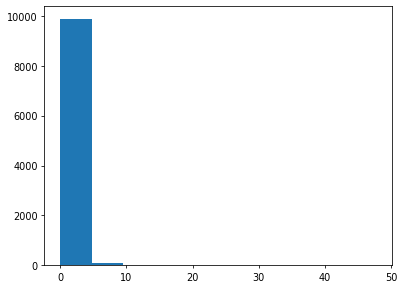

In [10]:
plt.hist(sig_samp);

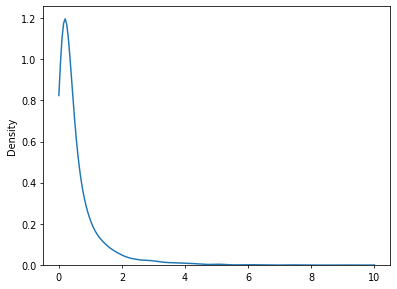

In [11]:
import seaborn as sns
sns.kdeplot(sig_samp, clip=(0, 10));

In [12]:
def noisify(x0):
    device = x0.device
    sig = (torch.randn([len(x0)])*1.2-1.2).exp().to(x0)
    sig = sig.clamp(0.02, 80.).reshape(-1,1,1,1) # we got nan at training
    noise = torch.randn_like(x0,device=device)
    c_skip,c_out,c_in = scaling(sig)
    noised_inp = x0 + noise*sig
    target = (x0-c_skip*noised_inp)/c_out
    return (noised_inp*c_in,sig.squeeze()),target

In [13]:
def collate_ddpm(b): return noisify(default_collate(b)[xl])
def dl_ddpm(ds): return DataLoader(ds, batch_size=bs, collate_fn=collate_ddpm, num_workers=8)

In [14]:
dls = DataLoaders(dl_ddpm(tds['train']), dl_ddpm(tds['test']))

In [15]:
dl = dls.train
(noised_input,sig),target = b = next(iter(dl))

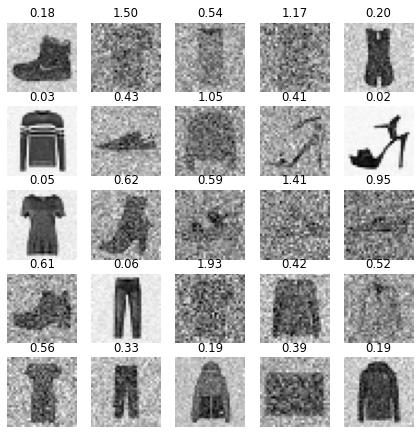

In [16]:
# Input
show_images(noised_input[:25], imsize=1.5, titles=fc.map_ex(sig[:25], '{:.02f}'))

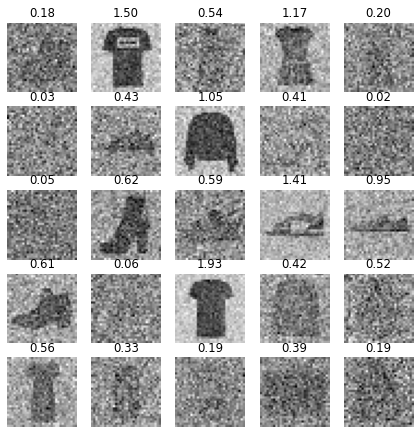

In [17]:
# Target
show_images(target[:25], imsize=1.5, titles=fc.map_ex(sig[:25], '{:.02f}'))

In [18]:
noised_input.mean(),noised_input.std(),target.mean(),target.std()

(tensor(-0.67229), tensor(1.02251), tensor(-0.40392), tensor(1.03631))

We cared about having unit variance, not much about mean here

# Training

In [19]:
class UNet(UNet2DModel):
    def forward(self, x): return super().forward(*x).sample

In [20]:
def init_ddpm(model):
    for o in model.down_blocks:
        for p in o.resnets:
            p.conv2.weight.data.zero_()
            for p in fc.L(o.downsamplers): init.orthogonal_(p.conv.weight)

    for o in model.up_blocks:
        for p in o.resnets: p.conv2.weight.data.zero_()

    model.conv_out.weight.data.zero_()

In [21]:
lr = 4e-3 # made smaller lr, because we are using bs=256 (less stable), not 512 (more stable)
epochs = 25
opt_func = partial(optim.Adam, eps=1e-5)
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
cbs = [DeviceCB(), MixedPrecision(), ProgressCB(plot=True), MetricsCB(), BatchSchedCB(sched)]
model = UNet(in_channels=1, out_channels=1, block_out_channels=(32, 64, 128, 256), norm_num_groups=8)
init_ddpm(model)
learn = Learner(model, dls, nn.MSELoss(), lr=lr, cbs=cbs, opt_func=opt_func)

In [ ]:
learn.fit(epochs)

In [22]:
# torch.save(learn.model, '../models/fashion_karras.pkl')
model = learn.model = torch.load('../models/fashion_karras.pkl',weights_only=False,map_location='cuda')

In [23]:
def denoise(target, noised_input): return target*c_out + noised_input*c_skip

Just solve for the x0 in the noisify function

In [24]:
with torch.no_grad():
    sigr = sig.cuda().reshape(-1,1,1,1)
    c_skip,c_out,c_in = scaling(sigr)
    targ_pred = learn.model((noised_input.cuda(),sig.cuda()))
    x0_pred = denoise(targ_pred, noised_input.cuda()/c_in)

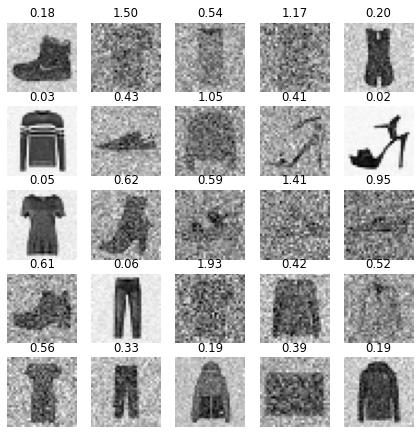

In [25]:
# Noised input
show_images(noised_input[:25], imsize=1.5, titles=fc.map_ex(sig[:25], '{:.02f}'))

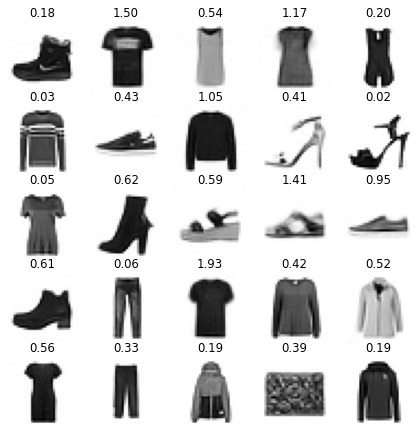

In [26]:
# Predicted x0
show_images(x0_pred[:25].clamp(-1,1), imsize=1.5, titles=fc.map_ex(sig[:25], '{:.02f}'))

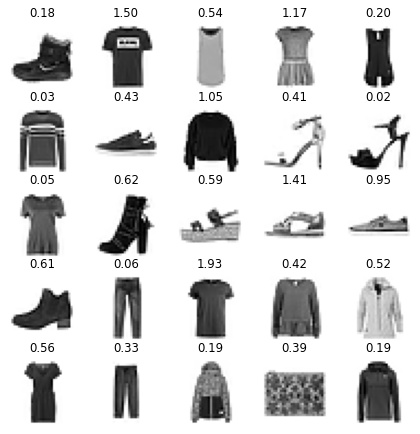

In [27]:
# Original image
show_images(denoise(target.cuda(), noised_input.cuda()/c_in)[:25], imsize=1.5, titles=fc.map_ex(sig[:25], '{:.02f}'))

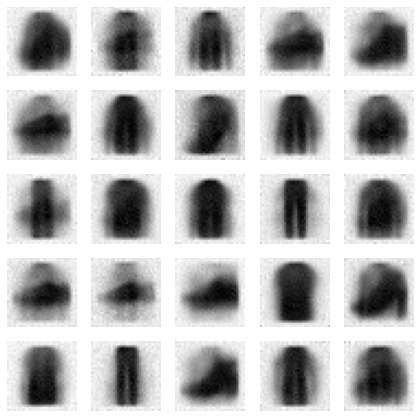

In [28]:
# look at when the sigma is high =80. , like the point is to
sig_r = tensor(80.).cuda().reshape(-1,1,1,1)
c_skip,c_out,c_in = scaling(sig_r)
x_r = torch.randn(32,1,32,32).to(model.device)*sig_r
with torch.no_grad():
    targ_preds = learn.model((x_r*c_in,sig_r.squeeze()))
    x0_pred = denoise(targ_preds, x_r)
show_images(x0_pred[:25], imsize=1.5)

- `x_r = torch.randn(32,1,32,32).to(model.device)*sig_r` -> the main equaiton is `noised = x0 + noise*sigma`, but the `x0` is already noise
- if we made the` x0 random noise` -> `std=1` , `noise*80` -> `std = 80`, so `x0` is completely drowned out ✓

In [29]:
x0_pred.max(),x0_pred.min(),x0_pred.mean(),x0_pred.std()

(tensor(0.58778, device='cuda:0'),
 tensor(-1.16470, device='cuda:0'),
 tensor(-0.51645, device='cuda:0'),
 tensor(0.47142, device='cuda:0'))

Idea is to see if it is in like range if it is in range like the the model not spitting garbage.

    training:
        sample sigma from log-normal
        add noise: noised = x0 + noise*sig
        normalize input: noised*c_in → unit variance
        compute target: (x0 - c_skip*noised)/c_out
        model learns: normalized_noisy → target

# Sampling

In [30]:
from miniai.fid import ImageEval

In [31]:
cmodel = torch.load('../models/data_aug2.pkl',weights_only=False,map_location='cuda')
del(cmodel[8])
del(cmodel[7])

bs = 2048
tds = dsd.with_transform(transformi)
dls = DataLoaders.from_dd(tds, bs, num_workers=fc.defaults.cpus)

dt = dls.train
xb,yb = next(iter(dt))

ie = ImageEval(cmodel, dls, cbs=[DeviceCB()])

In [32]:
sz = (1024,1,32,32)

In [33]:
# make a sigmas sched
def sigmas_karras(n, sigma_min=0.01, sigma_max=80, rho=7., device='cpu'):
    ramp = torch.linspace(0, 1, n)
    min_inv_rho = sigma_min**(1/rho) # This is just root 7
    max_inv_rho = sigma_max**(1/rho)
    sigmas = (max_inv_rho + ramp * (min_inv_rho-max_inv_rho))**rho
    return torch.cat([sigmas, tensor([0.])]).to(device) # last step sigma = 0 -> clean image

- We made it non linear here and made `(roots=7)` -> to make the model move fast at the beggining of the sampling and then spend more time at the finetuning at the end

In [34]:
torch.cat([tensor([3.,4.]), tensor([0.])])

tensor([3., 4., 0.])

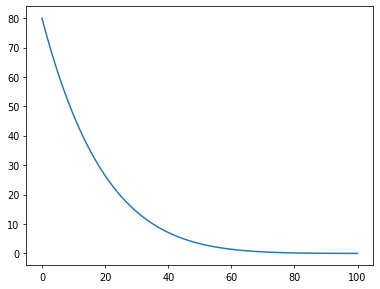

In [35]:
sk = sigmas_karras(100)
plt.plot(sk);

In [36]:
def denoise(model, x, sig):
    c_skip,c_out,c_in = scaling(sig)
    return model((x*c_in, sig))*c_out + x*c_skip

In [37]:
def sample(sampler,model,steps=100,sigma_max=80,sz=sz,**kwargs):
    preds = []
    x = torch.randn(sz).to(model.device)*sigma_max # *sigma -> make it the starting x0
    sigs = sigmas_karras(steps,sigma_max=sigma_max,device=model.device)
    for i in progress_bar(range(steps)):
        x = sampler(x,sigs,i,model,**kwargs)
        preds.append(x)
    return preds

In [38]:
@torch.no_grad()
def sample_euler(x, sigs, i ,model):
    sig,sig2 = sigs[i],sigs[i+1]
    denoised = denoise(model,x,sig)
    return x + (x-denoised)*(sig2-sig)/sig

This one is completely deterministic

- `*(sig2-sig)` -> how big is the step + gives `-ve`
- `sig` -> scale it

In [39]:
def get_ancestral_step(sigma_from, sigma_to, eta=1.):
    if not eta: return sigma_to, 0.
    var_to,var_from = sigma_to**2,sigma_from**2
    sigma_up = min(sigma_to, eta * (var_to * (var_from-var_to)/var_from)**0.5)
    return (var_to-sigma_up**2)**0.5, sigma_up

This is some math for calcuation how much (`original signal`,`randomness`)  we add

In [40]:
@torch.no_grad()
def sample_euler_ancestral(x, sigs, i, model, eta=1.):
    sig,sig2 = sigs[i],sigs[i+1]
    denoised = denoise(model,x,sig)
    sigma_down,sigma_up = get_ancestral_step(sig, sig2, eta=eta)
    x = x + (x-denoised)/sig*(sigma_down-sig) # scaling by sigma_down
    return x + torch.randn_like(x)*sigma_up  # scaling by sigma_up

This is as we were making in the DDPM -> adding noise back again after every step

In [41]:
@torch.no_grad()
def sample_heun(x, sigs, i, model, s_churn=0., s_tmin=0., s_tmax=float('inf'),s_noise=1.):
    sig,sig2 = sigs[i],sigs[i+1]
    # adding controlled noise before the denoising step to help escape local minima.
    n = len(sigs)
    gamma = min(s_churn/(n-1), 2**0.5-1) if s_tmin<=sig<=s_tmax else 0.
    eps = torch.randn_like(x) * s_noise
    sigma_hat = sig * (gamma+1)
    if gamma > 0: x = x + eps * (sigma_hat**2-sig**2)**0.5
    # Steps
    denoised = denoise(model,x,sig)
    d1 = (x-denoised)/sig
    dt = sig2 - sigma_hat # change in sigma , -ve
    x_2 = x + d1*dt
    if sig2==0: return x_2
    denoised2 = denoise(model,x_2,sig2)
    d2 = (x_2-denoised2)/sig2
    d_prime = (d1+d2)/2
    return x + d_prime*dt

- `float('inf')` -> infinity

In [42]:
preds = sample(sample_euler, model)
s = preds[-1]
print(f'{ie.fid(s), ie.kid(s)} \n {ie.fid(xb), ie.kid(xb)}')

<div><progress max="100" value="100"></progress> 100.00% [100/100 01:38&lt;00:00]</div>

(20.73876953125, 0.3980060815811157) 
 (1.461669921875, -0.11882232874631882)


In [43]:
s.min(),s.max()

(tensor(-1.06250, device='cuda:0'), tensor(1.31255, device='cuda:0'))

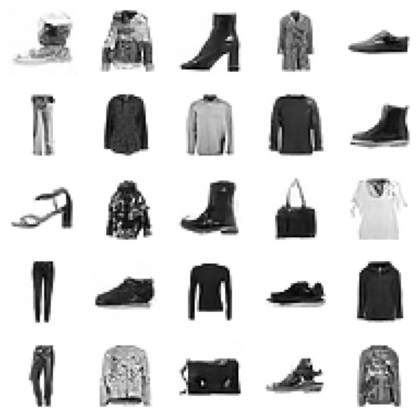

In [44]:
show_images(s[:25].clamp(-1,1), imsize=1.5)

In [45]:
preds = sample(sample_euler_ancestral, model)
s = preds[-1]
print(f'{ie.fid(s), ie.kid(s)} \n {ie.fid(xb), ie.kid(xb)}')

<div><progress max="100" value="100"></progress> 100.00% [100/100 01:39&lt;00:00]</div>

(27.281494140625, 0.60008305311203) 
 (1.461669921875, -0.11882232874631882)


In [46]:
preds = sample(partial(sample_euler_ancestral,eta=0.5), model)
s = preds[-1]
print(f'{ie.fid(s), ie.kid(s)} \n {ie.fid(xb), ie.kid(xb)}')

<div><progress max="100" value="100"></progress> 100.00% [100/100 01:40&lt;00:00]</div>

(20.884033203125, 0.24569593369960785) 
 (1.461669921875, -0.11882232874631882)


In [47]:
preds = sample(sample_heun, model,50)
s = preds[-1]
print(f'{ie.fid(s), ie.kid(s)} \n {ie.fid(xb), ie.kid(xb)}')

<div><progress max="50" value="50"></progress> 100.00% [50/50 01:37&lt;00:00]</div>

(24.601318359375, 0.2272752970457077) 
 (1.461669921875, -0.11882232874631882)


In [49]:
from scipy import integrate
def linear_multistep_coeff(order, t, i, j):
    if order - 1 > i: raise ValueError(f'Order {order} too high for step {i}')

    def fn(tau):
        prod = 1.
        for k in range(order):
            if j == k: continue
            prod *= (tau - t[i - k]) / (t[i - j] - t[i - k])
        return prod

    return integrate.quad(fn, t[i], t[i + 1], epsrel=1e-4)[0]

In [50]:
@torch.no_grad()
def sample_lms(model, steps=100, order=4, sigma_max=80.):
    preds = []
    x = torch.randn(sz).to(model.device) * sigma_max
    sigs = sigmas_karras(steps, device=model.device, sigma_max=sigma_max)
    ds = []
    for i in progress_bar(range(len(sigs) - 1)):
        sig = sigs[i]
        denoised = denoise(model, x, sig)
        d = (x - denoised) / sig
        ds.append(d)
        if len(ds) > order: ds.pop(0)
        cur_order = min(i + 1, order)
        coeffs = [linear_multistep_coeff(cur_order, sigs, i, j) for j in range(cur_order)]
        x = x + sum(coeff * d for coeff, d in zip(coeffs, reversed(ds)))
        preds.append(x)
    return preds

- This one uses 4 steps not (1 as euler or 2 as heun)